# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

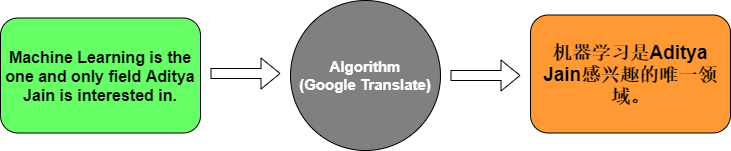

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [2]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [6]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.1429 - loss: 2.4798 - val_accuracy: 0.0000e+00 - val_loss: 2.4878
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.5714 - loss: 2.4690 - val_accuracy: 0.0000e+00 - val_loss: 2.4902
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.5714 - loss: 2.4573 - val_accuracy: 0.0000e+00 - val_loss: 2.4929
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5714 - loss: 2.4443 - val_accuracy: 0.0000e+00 - val_loss: 2.4959
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5714 - loss: 2.4296 - val_accuracy: 0.0000e+00 - val_loss: 2.4993
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5714 - loss: 2.4127 - val_accuracy: 0.0000e+00 - val_loss: 2.5033
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.5714 - loss: 2.3931 - val_accuracy: 0.0000e+00 - val_loss: 2.5078
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5714 - loss: 2.3701 - val_accuracy: 

In [8]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1- Embedding is takes word index and convert it to vector of numbers

2- Encoder LSTM takes the sentence as input and understand its meaning

3- Decoder LSTM generates the output sentence by word

4- softmax convert the scores to probabilites to use it to predict next word

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
 
EN_COL, FR_COL = "English words/sentences", "French words/sentences"
MAX_WORDS = 6        # only short pairs
N_PAIRS = 10000      # small enough for a laptop
NUM_WORDS = 2000     # vocabulary cap per language
 
def clean(text):
    text = str(text).lower().strip()
    return re.sub(r"(['’])", r"\1 ", text)      # j'ai -> j' ai
 
df = pd.read_csv("eng_-french.csv", encoding="utf-8")
df = df.dropna(subset=[EN_COL, FR_COL])
df[EN_COL] = df[EN_COL].map(clean)
df[FR_COL] = df[FR_COL].map(clean)
 
short = (df[EN_COL].str.split().str.len() <= MAX_WORDS) & \
        (df[FR_COL].str.split().str.len() <= MAX_WORDS)
df = df[short].drop_duplicates(subset=[EN_COL])
df = df.sample(n=min(N_PAIRS, len(df)), random_state=42)
 
df[FR_COL] = df[FR_COL] + " endseq"             # lets the model learn where to stop
 
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
english_train, french_train = train_df[EN_COL].tolist(), train_df[FR_COL].tolist()
english_test, french_test = test_df[EN_COL].tolist(), test_df[FR_COL].tolist()
 
print(f"Training pairs: {len(english_train)} | Test pairs: {len(english_test)}")
print(f"Example: {english_train[0]} -> {french_train[0]}")

Training pairs: 8000 | Test pairs: 2000
Example: tom is a spy. -> tom est un espion. endseq


In [2]:
import time
import tensorflow as tf
 
# Keep the laptop responsive (must run before TensorFlow does any work)
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print("Thread limits already set (restart the kernel to change them).")
 
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
 
eng_tok = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
frn_tok = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
eng_tok.fit_on_texts(english_train)             # fit on training text only
frn_tok.fit_on_texts(french_train)
 
def encode(tok, texts, maxlen=None):
    seqs = tok.texts_to_sequences(texts)
    if maxlen is None:
        maxlen = max(len(s) for s in seqs)
    return pad_sequences(seqs, maxlen=maxlen, padding="post", truncating="post"), maxlen
 
eng_train_pad, eng_max_len = encode(eng_tok, english_train)
frn_train_pad, frn_max_len = encode(frn_tok, french_train)
eng_test_pad, _ = encode(eng_tok, english_test, eng_max_len)
frn_test_pad, _ = encode(frn_tok, french_test, frn_max_len)
 
train_w = (frn_train_pad != 0).astype("float32")    # ignore padding in the loss
test_w = (frn_test_pad != 0).astype("float32")
 
eng_vocab = min(NUM_WORDS, len(eng_tok.word_index) + 1)
frn_vocab = min(NUM_WORDS, len(frn_tok.word_index) + 1)
print("max lengths (en, fr):", eng_max_len, frn_max_len)
print("vocab sizes (en, fr):", eng_vocab, frn_vocab)

max lengths (en, fr): 7 9
vocab sizes (en, fr): 2000 2000


In [5]:
from tensorflow.keras import layers
 
task2_model = tf.keras.Sequential([
    layers.Input(shape=(eng_max_len,)),
    layers.Embedding(eng_vocab, 64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),              # encoder
    layers.Dropout(0.3),
    layers.RepeatVector(frn_max_len),
    layers.LSTM(128, return_sequences=True),            # decoder
    layers.Dropout(0.3),
    layers.TimeDistributed(layers.Dense(frn_vocab, activation="softmax")),
])
task2_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
task2_model.summary()
 
 
class TimeLimit(tf.keras.callbacks.Callback):
    """Stop training after N minutes so the laptop never gets stuck."""
    def __init__(self, minutes):
        super().__init__()
        self.limit = minutes * 60
    def on_train_begin(self, logs=None):
        self.start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if time.time() - self.start > self.limit:
            print(f"\nTime limit reached after epoch {epoch + 1}; stopping.")
            self.model.stop_training = True
 
 
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                     restore_best_weights=True),
    TimeLimit(minutes=15),
]
 
history = task2_model.fit(
    eng_train_pad,
    np.expand_dims(frn_train_pad, -1),
    sample_weight=train_w,
    validation_split=0.1,
    epochs=100,
    batch_size=64,
    callbacks=callbacks,
    verbose=2,                  # one line per epoch
)
 
test_loss, test_acc = task2_model.evaluate(
    eng_test_pad, np.expand_dims(frn_test_pad, -1),
    sample_weight=test_w, verbose=0)
print(f"Test loss: {test_loss:.4f}; token accuracy: {test_acc:.4f}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 7, 64)          │       128,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 9, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 9, 128)         │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 9, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 9, 2000)        │       258,000 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 583,632 (2.23 MB)

 Trainable params: 583,632 (2.23 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
113/113 - 6s - 55ms/step - accuracy: 0.1091 - loss: 3.7365 - val_accuracy: 0.1111 - val_loss: 3.3000
Epoch 2/100
113/113 - 3s - 26ms/step - accuracy: 0.1232 - loss: 3.2392 - val_accuracy: 0.1303 - val_loss: 3.1328
Epoch 3/100
113/113 - 3s - 25ms/step - accuracy: 0.1411 - loss: 3.1038 - val_accuracy: 0.1506 - val_loss: 3.0264
Epoch 4/100
113/113 - 3s - 24ms/step - accuracy: 0.1502 - loss: 3.0238 - val_accuracy: 0.1546 - val_loss: 2.9757
Epoch 5/100
113/113 - 3s - 24ms/step - accuracy: 0.1535 - loss: 2.9680 - val_accuracy: 0.1567 - val_loss: 2.9342
Epoch 6/100
113/113 - 3s - 24ms/step - accuracy: 0.1548 - loss: 2.9300 - val_accuracy: 0.1624 - val_loss: 2.9138
Epoch 7/100
113/113 - 3s - 24ms/step - accuracy: 0.1590 - loss: 2.8888 - val_accuracy: 0.1674 - val_loss: 2.8673
Epoch 8/100
113/113 - 3s - 24ms/step - accuracy: 0.1673 - loss: 2.8429 - val_accuracy: 0.1769 - val_loss: 2.8243
Epoch 9/100
113/113 - 3s - 25ms/step - accuracy: 0.1747 - loss: 2.7909 - val_accuracy: 0.1799 - 

In [6]:
def translate_task2(sentence):
    seq = eng_tok.texts_to_sequences([clean(sentence)])
    pad = pad_sequences(seq, maxlen=eng_max_len, padding="post", truncating="post")
    ids = np.argmax(task2_model.predict(pad, verbose=0)[0], axis=-1)
    words = []
    for i in ids:
        w = frn_tok.index_word.get(int(i), "")
        if w == "endseq":
            break
        if w and w != "<OOV>":
            words.append(w)
    return " ".join(words)
 
for i in range(8):
    print("English:  ", english_test[i])
    print("Expected: ", french_test[i].replace(" endseq", ""))
    print("Predicted:", translate_task2(english_test[i]), "\n")

English:   tom opened the window a crack.
Expected:  tom entrouvrit la fenêtre.
Predicted: tom a une 

English:   the car is very fast.
Expected:  la voiture est très rapide.
Predicted: mon voiture est très 

English:   it' s a wonderful opportunity.
Expected:  c' est une merveilleuse opportunité.
Predicted: c' est un 

English:   all the apples are here.
Expected:  toutes les pommes sont ici.
Predicted: les les sont sont 

English:   how' s your old lady doing?
Expected:  comment va ta femme ?
Predicted: où est ton ton 

English:   dogs bark.
Expected:  des chiens aboient.
Predicted: les les 

English:   let' s go back inside.
Expected:  retournons à l' intérieur.
Predicted: vous 

English:   democracy encourages freedom.
Expected:  la démocratie encourage la liberté.
Predicted:  

